# 05 - Synthetic population

The generator is fitted on the 424 training records only. It produces predictor variables, never a
Choice label. Travel times and costs are not synthesised; they are rebuilt from the synthetic distance
with the speed and fare rules recovered in the audit. Three methods are compared.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
from src import synthetic_generation as SG
comp = pd.read_csv(RES / "synthetic_method_comparison.csv")
comp.set_index("method").T

method,bootstrap,copula,cart
mean_marginal_distance,0.006258,0.020703,0.011177
max_marginal_distance,0.013766,0.119645,0.057004
association_mad,0.043888,0.077633,0.042491
discriminator_auc,0.297714,0.746616,0.492212
records_needing_repair_pct,0.720000,31.260000,1.500000
viol_children_leave_no_adult,7.000000,116.000000,25.000000
viol_workers_exceed_household,29.000000,74.000000,43.000000
viol_car_available_without_car,0.000000,579.000000,0.000000
viol_twow_available_without_twow,0.000000,463.000000,0.000000
viol_short_trip_without_walk_option,0.000000,331.000000,0.000000


* **Bootstrap** reproduces the marginals best but 99.3% of its records are copies of real people;
  it fails the memorisation rule and serves only as a reference.
* **Gaussian copula** creates new records, but a random forest separates them from real ones easily
  (AUC 0.747), associations are distorted the most, and 31% of records break a logical rule before
  repair (for example, car available in a household without a car).
* **Sequential CART** keeps the associations best (mean absolute difference in Cramér's V 0.042),
  its records are indistinguishable from real ones (AUC 0.492), only 1.5% need repair, and only 0.38%
  coincide with a training record.

The rule chosen in advance (exact copies no more than twice the holdout rate plus one point, then the
AUC closest to 0.5) selects CART. Its leaf size was set to 10 after this check:

In [2]:
pd.read_csv(RES / "synthetic_cart_leaf_sensitivity.csv")

,min_leaf,mean_marginal_distance,association_mad,discriminator_auc,records_needing_repair_pct,exact_copy_share_synthetic,exact_copy_share_holdout,median_dcr_synthetic,median_dcr_holdout,share_synthetic_closer_than_holdout_p5
0,5,0.011208,0.037769,0.454214,1.14,0.0132,0.0,0.099809,0.142857,0.1534
1,10,0.011177,0.042491,0.492212,1.50,0.0038,0.0,0.142910,0.142857,0.0920
2,15,0.013563,0.041339,0.492109,1.78,0.0018,0.0,0.143123,0.142857,0.0796
3,20,0.013353,0.043954,0.536415,2.46,0.0006,0.0,0.143176,0.142857,0.0640


With leaf size 5, 15% of synthetic people sit closer to a training record than 95% of real held-out
people do (memorisation). With 10, the median distance to the closest training record equals the
holdout's (0.143) and only 9% fall below the holdout's 5th percentile, at almost no cost in fidelity.

In [3]:
pop = pd.read_csv(C.Paths().synthetic / "synthetic_population.csv")
print(pop.shape); pop.head()

(5000, 35)


,ID,Income,Age,Education,Occup,Gender,Area_Type,Dwelling,HH_Size,Children,Working_Adults,Car_Ownership,TwoW_Ownership,ParkingSpace,Car_AV,TwoW_AV,Trip_Purpose,SAPT,Distance_km,Walk_AV,Auto_AV,Bus_AV,Adults,LocalTrain_AV,walk_time_min,TwoW_time_min,auto_time_min,car_time_min,bus_time_min,local_train_time_min,TC_Car,TC_2W,TC_Auto,TC_Bus,TC_LocalTrain
0,1,3,2,1,5,1,1,1,4,2,1,1,1,1,1,1,2,1,2.0,0,1,0,2,1,30.0,4.8,6.0,5.5,7.1,3.4,9.0,3.0,19.0,7.0,5.0
1,2,1,2,3,5,1,0,4,4,2,1,1,1,0,1,1,2,1,4.5,1,0,0,2,1,67.5,10.8,13.5,12.3,15.9,7.7,20.0,7.0,44.0,11.0,5.0
2,3,3,2,1,3,1,1,2,8,0,2,1,1,1,1,1,2,1,15.3,0,0,0,8,1,229.5,36.7,45.9,41.7,54.0,26.2,68.0,25.0,150.0,25.0,5.0
3,4,2,2,1,2,1,1,4,6,2,2,1,2,0,0,1,2,1,1.6,1,0,0,4,1,24.0,3.8,4.8,4.4,5.6,2.7,7.0,3.0,15.0,7.0,5.0
4,5,1,2,3,5,1,0,4,3,0,3,0,1,0,0,1,2,1,1.8,1,1,0,3,1,27.0,4.3,5.4,4.9,6.4,3.1,8.0,3.0,17.0,7.0,5.0


In [4]:
pd.read_csv(RES / "synthetic_marginal_fidelity.csv").round(4)

,variable,metric,distance
0,Income,total variation distance,0.0087
1,Age,total variation distance,0.0111
2,Education,total variation distance,0.0051
3,Occup,total variation distance,0.0093
4,Gender,total variation distance,0.0007
5,Area_Type,total variation distance,0.0037
6,Dwelling,total variation distance,0.0118
7,HH_Size,total variation distance,0.0070
8,Children,total variation distance,0.0151
9,Working_Adults,total variation distance,0.0070


In [5]:
pd.read_csv(RES / "synthetic_moments.csv").round(2)

,variable,data,mean,sd,p5,p25,p50,p75,p95
0,Distance_km,real,7.20,7.74,0.82,1.68,4.05,10.6,20.92
1,Distance_km,synthetic,7.77,9.41,0.70,1.60,4.30,10.6,25.20
2,HH_Size,real,4.35,1.49,2.00,3.00,4.00,5.0,7.00
3,HH_Size,synthetic,4.35,1.48,2.00,3.00,4.00,5.0,7.00
4,Children,real,1.10,1.23,0.00,0.00,1.00,2.0,3.00
5,Children,synthetic,1.07,1.19,0.00,0.00,1.00,2.0,3.00
6,Working_Adults,real,1.63,0.89,1.00,1.00,1.00,2.0,3.00
7,Working_Adults,synthetic,1.62,0.88,1.00,1.00,1.00,2.0,3.00
8,Car_Ownership,real,0.76,0.64,0.00,0.00,1.00,1.0,2.00
9,Car_Ownership,synthetic,0.77,0.63,0.00,0.00,1.00,1.0,2.00


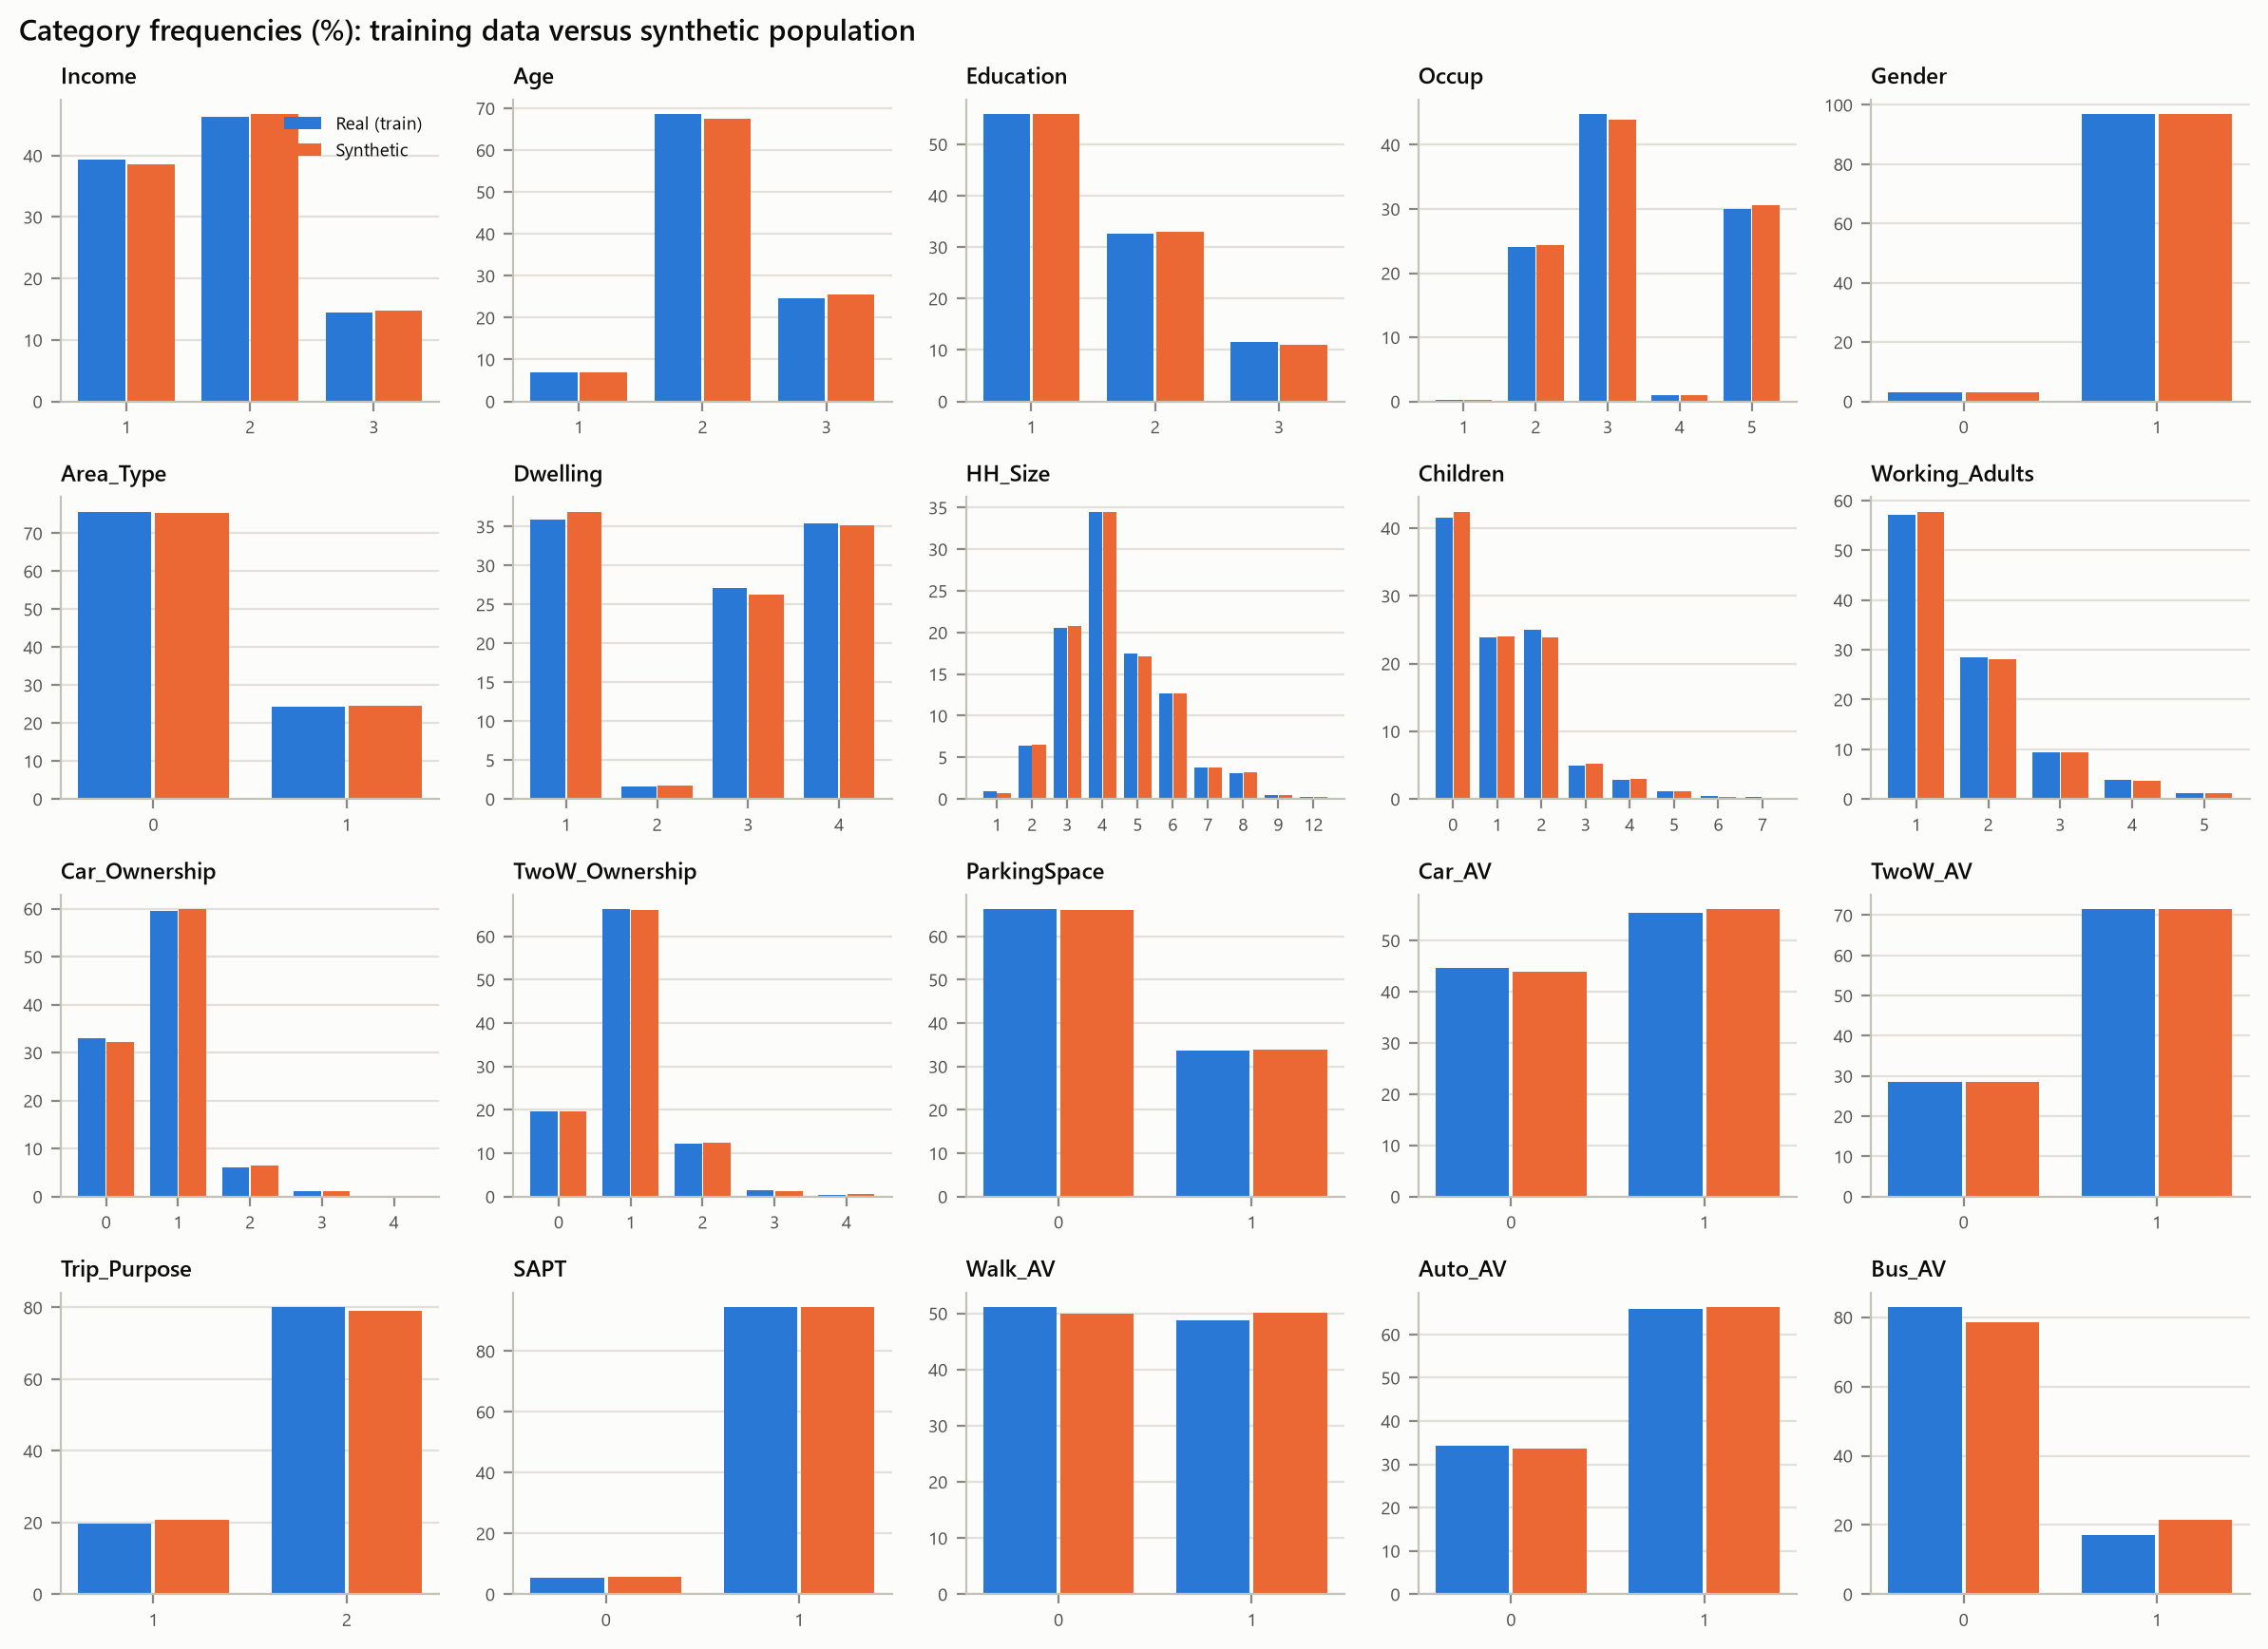

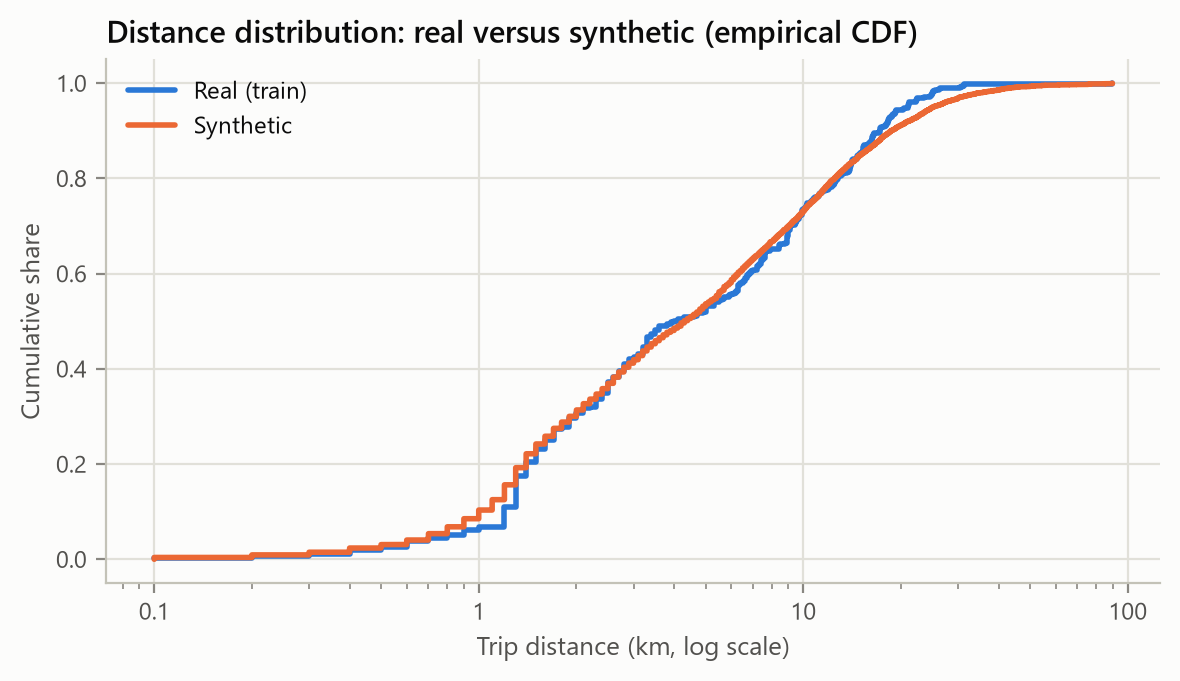

In [6]:
fig("synthetic_marginals.png", 1000)
fig("synthetic_distance.png", 650)

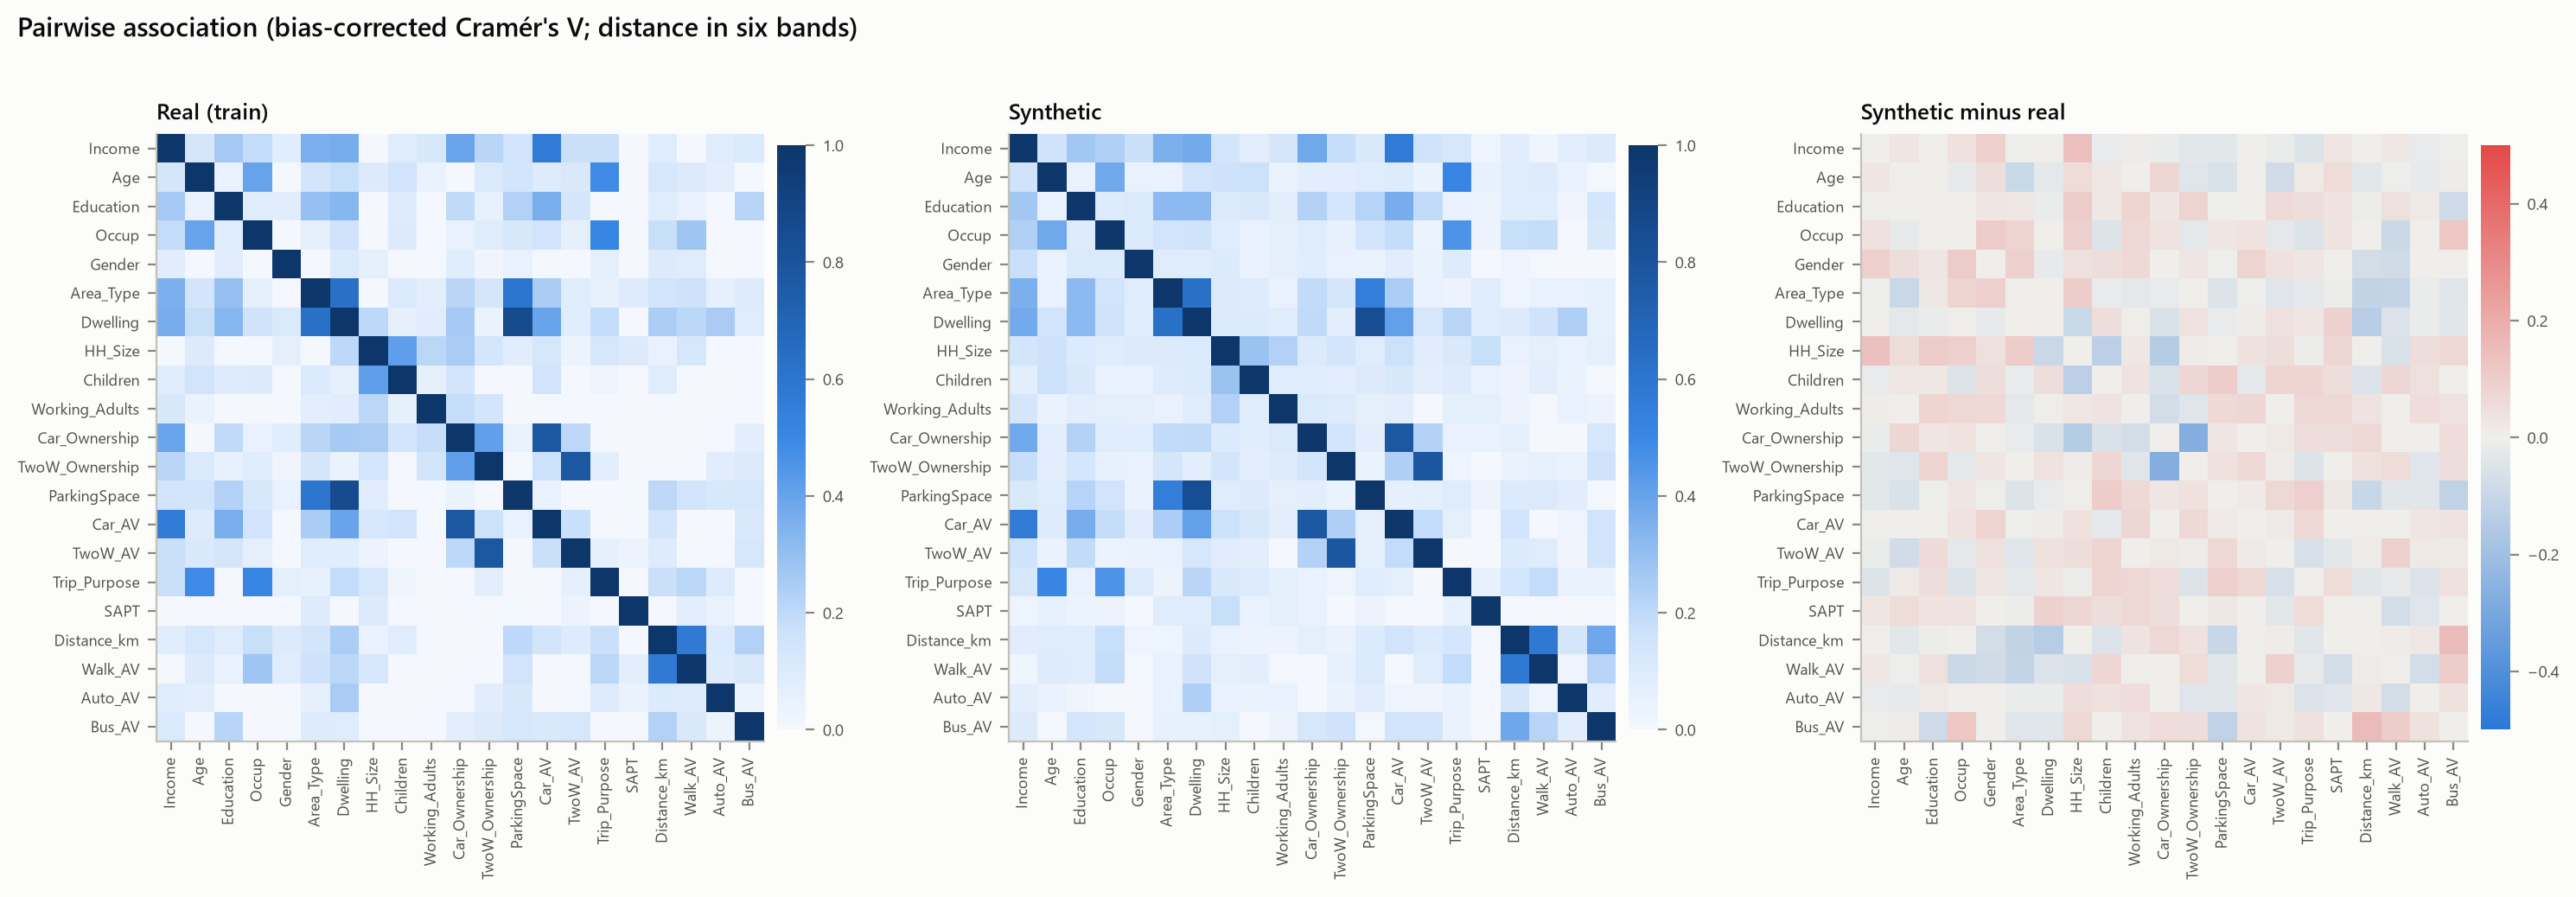

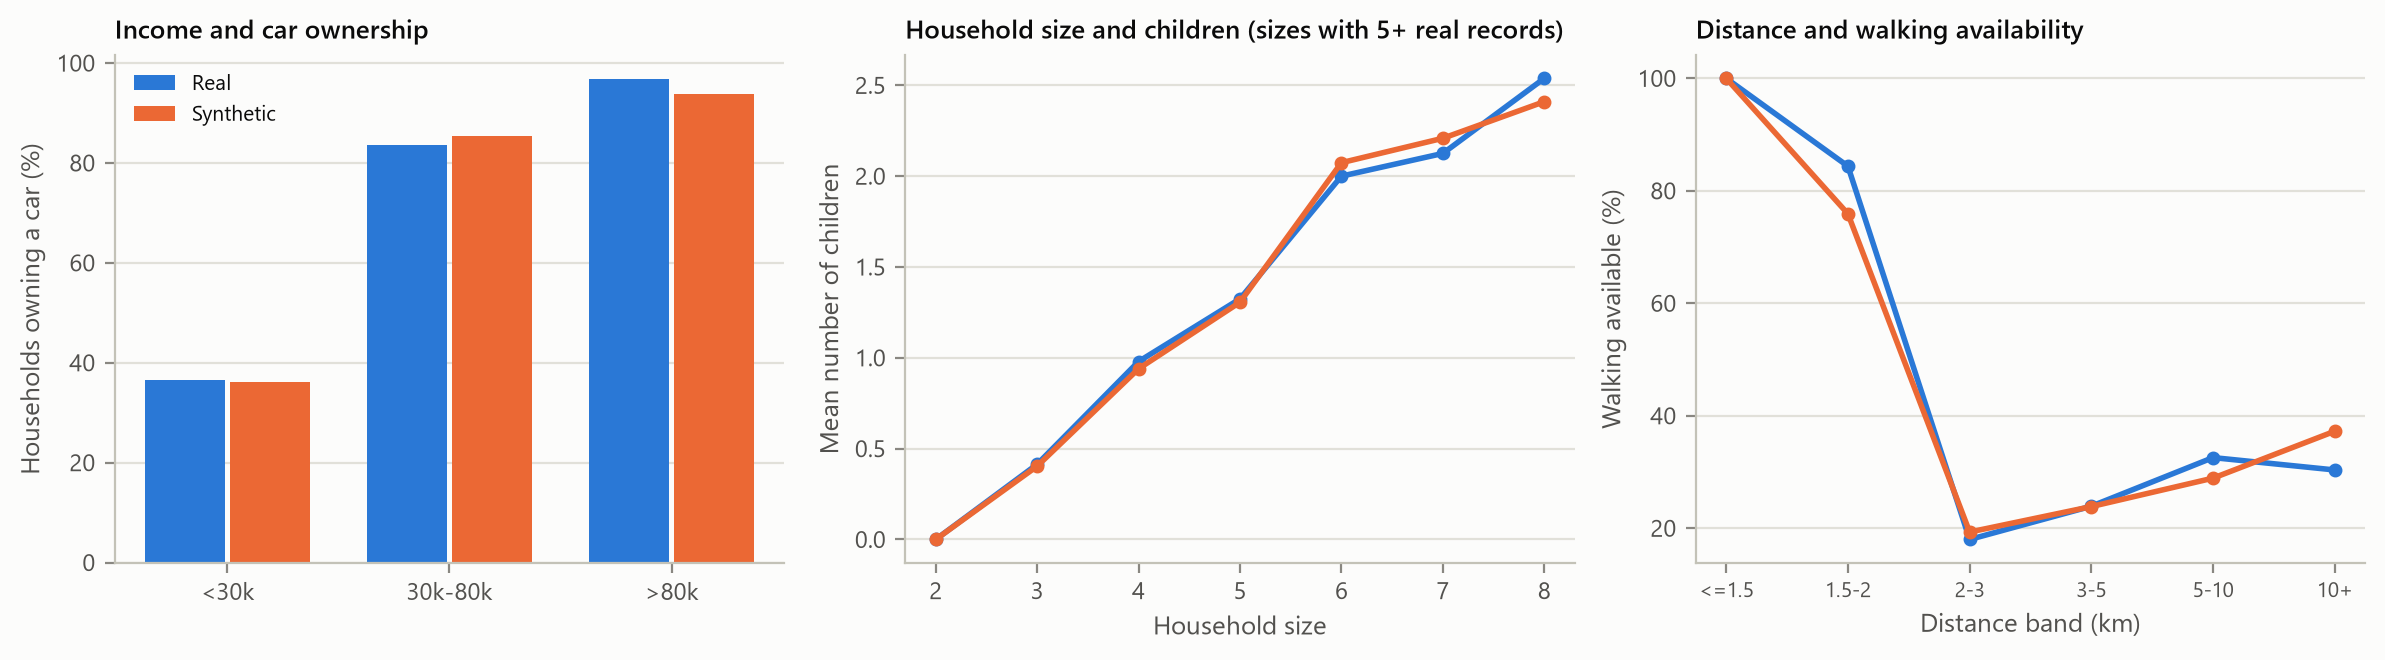

In [7]:
fig("synthetic_associations.png", 1000)
fig("synthetic_pairwise.png", 1000)

Category frequencies match to within about 1.3 percentage points for every variable except bus
availability (21.5% of synthetic commuters against 17.0% in the training data). The CART synthesis
slightly weakens the association between car and two-wheeler ownership
and between household size and children, and slightly strengthens the link between distance and bus
availability. Income still drives car ownership, children grow with household size and walking
availability falls with distance as in the real data.

Logical constraints on the saved population:

In [8]:
train = pd.read_csv(C.Paths().processed / "train.csv")
print(SG.constraint_violations(pop, train["Distance_km"].min(), train["Distance_km"].max()))
print("adults >= 1:", (pop["Adults"] >= 1).all(), "| adults + children = size:", (pop["Adults"] + pop["Children"] == pop["HH_Size"]).all())
print("Choice column present:", "Choice" in pop.columns)

{'children_leave_no_adult': 0, 'workers_exceed_household': 0, 'car_available_without_car': 0, 'twow_available_without_twow': 0, 'short_trip_without_walk_option': 0, 'distance_outside_observed_range': 0}
adults >= 1: True | adults + children = size: True
Choice column present: False


The population mirrors the survey sample. It is not calibrated to census totals for any city, so it
should be read as "a larger population that looks like our respondents", not as Mumbai.